# ML-06 — Signal Audit: Do the Flags Hold?

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Hammad-vibes/FlyRank-Internship/blob/main/work/notebooks/w04_signal_audit.ipynb?flush_cache=true)

This skeleton is yours to fill. Work the sections **in order** — each one has a one-line hint. Simple words, honest numbers.

> Working with an AI assistant? Tell it to read `skills/README.md` first and load the one skill this assignment names on its card.

## 1. Distributions

Before testing anything I look at the five fields. Search data usually has heavy tails: a few pages have huge impressions and most have very little. The code prints the quantiles and the ratio of the 99th percentile to the median (a big ratio means a heavy tail), then draws log-scale histograms. Because of the tail, buckets in section 2 are built from quantiles, not equal-width ranges.

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

rows: 17431 | clients: 29 | overall decline rate: 0.442


,0.01,0.1,0.25,0.5,0.75,0.9,0.99,p99 / median
impressions_h1,234.600,765.000,1373.000,2626.000,5151.500,9767.000,29173.800,11.1
clicks_h1,5.000,5.000,7.000,10.000,19.000,36.000,130.700,13.1
ctr_h1,0.001,0.002,0.003,0.005,0.008,0.013,0.034,6.8
avg_position_h1,1.201,2.300,3.273,4.965,10.202,23.161,39.519,8.0
active_days_h1,5.000,13.000,15.000,15.000,15.000,15.000,15.000,1.0


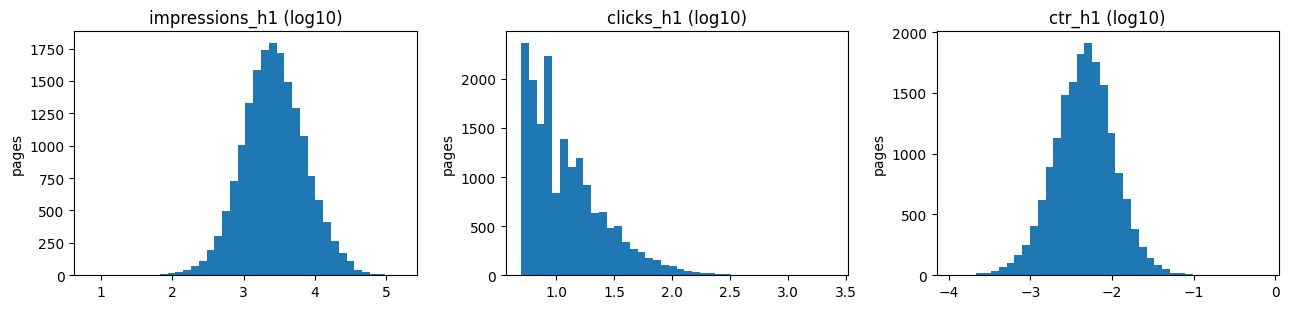

In [1]:
# This cell is for CODE (numbers, a query, a check).
# Write your text answer in the cell ABOVE this one — typing sentences here breaks Run All.
import duckdb, numpy as np, pandas as pd
import matplotlib.pyplot as plt
from google.colab import userdata

con = duckdb.connect()
con.execute(f"CREATE SECRET (TYPE huggingface, TOKEN '{userdata.get('HF_TOKEN')}')")
MAR = "hf://datasets/FlyRank/internship-warehouse/fact_content_daily_performance/month=2026-03/data_0.parquet"
con.execute(f"CREATE VIEW mar AS SELECT * FROM read_parquet('{MAR}')")

frame = con.sql("""
SELECT client_hash_id, content_hash_id,
  SUM(gsc_impressions)  FILTER (WHERE report_date <= DATE '2026-03-15') AS impressions_h1,
  SUM(gsc_clicks)       FILTER (WHERE report_date <= DATE '2026-03-15') AS clicks_h1,
  AVG(gsc_avg_position) FILTER (WHERE report_date <= DATE '2026-03-15') AS avg_position_h1,
  COUNT(*) FILTER (WHERE report_date <= DATE '2026-03-15' AND gsc_impressions > 0) AS active_days_h1,
  SUM(gsc_clicks)       FILTER (WHERE report_date >  DATE '2026-03-15') AS clicks_h2
FROM mar
WHERE gsc_data_available IS TRUE
GROUP BY 1, 2
""").df()

df = frame.copy()
df["clicks_h2"] = df["clicks_h2"].fillna(0)
df["ctr_h1"] = df["clicks_h1"] / df["impressions_h1"].replace(0, np.nan)
FEATURES = ["impressions_h1", "clicks_h1", "ctr_h1", "avg_position_h1", "active_days_h1"]
df = df[df["clicks_h1"] >= 5].dropna(subset=FEATURES).copy()
df["label"] = (df["clicks_h2"] < 0.8 * df["clicks_h1"]).astype(int)   # only for testing signals
df = df.reset_index(drop=True)
print("rows:", len(df), "| clients:", df["client_hash_id"].nunique(), "| overall decline rate:", round(df["label"].mean(), 3))

q = df[FEATURES].quantile([0.01, 0.10, 0.25, 0.50, 0.75, 0.90, 0.99]).T.round(3)
q["p99 / median"] = (q[0.99] / q[0.50]).round(1)
display(q)

fig, axes = plt.subplots(1, 3, figsize=(13, 3.2))
for ax, col in zip(axes, ["impressions_h1", "clicks_h1", "ctr_h1"]):
    vals = df[col][df[col] > 0]
    ax.hist(np.log10(vals), bins=40)
    ax.set_title(col + " (log10)"); ax.set_ylabel("pages")
plt.tight_layout(); plt.show()

## 2. Signal test #1 / #2 / #3 (verdict each)

Each signal is a plain idea a rule could lean on, tested with one bucket table (5 equal-sized buckets, `n` printed per bucket) and one verdict:

- **Signal 1, volume:** pages with *fewer* h1 impressions decline more. (This is the idea my Week-4 rule uses.)
- **Signal 2, CTR vs position (the CTR-fix signal):** pages whose CTR is *low for their position* decline more. CTR is divided by the median CTR of pages in the same position band, so a page is compared with its peers.
- **Signal 3, activity:** pages active on *fewer days* in h1 decline more.

**Verdict rule (fixed before looking at results):** FALSE if the lowest and highest bucket differ by less than 0.02 in decline rate; CONFIRMED if the direction matches my hypothesis and the buckets move steadily in that direction; OPPOSITE if the direction is reversed and steady; MIXED otherwise. The code prints the verdicts, and the plain-words reading is printed below the tables from the same numbers, so the text always matches the run. A clearly explained negative is as useful as a positive.

In [2]:
# This cell is for CODE (numbers, a query, a check).
# Write your text answer in the cell ABOVE this one — typing sentences here breaks Run All.
def bucket_table(d, col, q=5):
    b = pd.qcut(d[col], q=q, duplicates="drop")
    t = (d.assign(bucket=b).groupby("bucket", observed=True)
           .agg(n=("label", "size"), decline_rate=("label", "mean"))
           .round(3))
    return t

def verdict(t, hypothesis):
    """hypothesis: 'down' = decline rate should FALL as the signal rises; 'up' = should RISE."""
    r = t["decline_rate"].values
    gap = r[-1] - r[0]
    rho = np.corrcoef(np.arange(len(r)), r)[0, 1]
    if abs(gap) < 0.02:
        return "FALSE", gap, rho
    expected_sign = -1 if hypothesis == "down" else 1
    same = np.sign(gap) == expected_sign
    steady = abs(rho) >= 0.8
    if same and steady: return "CONFIRMED", gap, rho
    if (not same) and steady: return "OPPOSITE", gap, rho
    return "MIXED", gap, rho

df["pos_band"] = pd.cut(df["avg_position_h1"], [0, 3, 10, 20, 1000], labels=["1-3", "4-10", "11-20", "20+"])
df["ctr_vs_pos"] = df["ctr_h1"] / df.groupby("pos_band", observed=True)["ctr_h1"].transform("median")

signals = {
    "1) volume: impressions_h1 (fewer = more decline)":  ("impressions_h1", "down"),
    "2) CTR vs position: ctr_vs_pos (lower = more decline)": ("ctr_vs_pos", "down"),
    "3) activity: active_days_h1 (fewer = more decline)": ("active_days_h1", "down"),
}
results = {}
print("overall decline rate:", round(df["label"].mean(), 3), "| rows:", len(df), "\n")
for name, (col, hyp) in signals.items():
    t = bucket_table(df, col)
    v, gap, rho = verdict(t, hyp)
    results[name] = (v, gap, rho, t)
    print("=" * 70); print(name); print(t)
    print(f"-> VERDICT: {v}  (top bucket minus bottom bucket = {gap:+.3f}, steadiness rho = {rho:+.2f})\n")

overall decline rate: 0.442 | rows: 17431 

1) volume: impressions_h1 (fewer = more decline)
                       n  decline_rate
bucket                                
(6.999, 1172.0]     3488         0.509
(1172.0, 2054.0]    3487         0.470
(2054.0, 3363.0]    3485         0.430
(3363.0, 6152.0]    3485         0.412
(6152.0, 161575.0]  3486         0.390
-> VERDICT: CONFIRMED  (top bucket minus bottom bucket = -0.119, steadiness rho = -0.99)

2) CTR vs position: ctr_vs_pos (lower = more decline)
                                  n  decline_rate
bucket                                           
(0.033299999999999996, 0.505]  3487         0.414
(0.505, 0.823]                 3486         0.449
(0.823, 1.218]                 3486         0.436
(1.218, 1.933]                 3486         0.452
(1.933, 151.89]                3486         0.460
-> VERDICT: OPPOSITE  (top bucket minus bottom bucket = +0.046, steadiness rho = +0.84)

3) activity: active_days_h1 (fewer = more decline)


/usr/local/lib/python3.13/dist-packages/numpy/lib/_function_base_impl.py:2991: RuntimeWarning: Degrees of freedom <= 0 for slice
  c = cov(x, y, rowvar, dtype=dtype)
/usr/local/lib/python3.13/dist-packages/numpy/lib/_function_base_impl.py:2848: RuntimeWarning: divide by zero encountered in divide
  c *= np.true_divide(1, fact)
/usr/local/lib/python3.13/dist-packages/numpy/lib/_function_base_impl.py:2848: RuntimeWarning: invalid value encountered in multiply
  c *= np.true_divide(1, fact)


In [3]:
# This cell is for CODE (numbers, a query, a check).
# Write your text answer in the cell ABOVE this one — typing sentences here breaks Run All.
print("PLAIN-WORDS READING (generated from the numbers above):")
for name, (v, gap, rho, t) in results.items():
    lo, hi = t["decline_rate"].iloc[0], t["decline_rate"].iloc[-1]
    print(f"- {name}: {v}. Lowest bucket declined {lo:.3f}, highest bucket {hi:.3f}; "
          f"smallest bucket has n = {int(t['n'].min())}.")
print("\nRemember: observed in one month, directional only. A bucket gap is not a cause.")

PLAIN-WORDS READING (generated from the numbers above):
- 1) volume: impressions_h1 (fewer = more decline): CONFIRMED. Lowest bucket declined 0.509, highest bucket 0.390; smallest bucket has n = 3485.
- 2) CTR vs position: ctr_vs_pos (lower = more decline): OPPOSITE. Lowest bucket declined 0.414, highest bucket 0.460; smallest bucket has n = 3486.
- 3) activity: active_days_h1 (fewer = more decline): FALSE. Lowest bucket declined 0.442, highest bucket 0.442; smallest bucket has n = 17431.

Remember: observed in one month, directional only. A bucket gap is not a cause.


## 3. The flag-linked test

FlyRank's CTR-fix logic leans on the CTR-vs-position signal: a page that ranks well but earns fewer clicks than its peers has a title or snippet that may not be doing its job. **The rule's assumption I can test:** are pages with a *low CTR for a page-1 position* in trouble in the second half of the month (do they decline more than other page-1 pages)?

Test: among pages with average position 10 or better, compare pages whose CTR is at most half the peer median (`ctr_vs_pos <= 0.5`) with the rest. Both groups print their n and a rough standard error (`sqrt(p(1-p)/n)`) so I can see whether a gap is bigger than noise.

What this can and cannot say: it checks whether the flag *points at pages that decline more*. It does not show that fixing the title would recover clicks. That needs a before/after on pages that were actually edited, which this data cannot give me.

In [4]:
# This cell is for CODE (numbers, a query, a check).
# Write your text answer in the cell ABOVE this one — typing sentences here breaks Run All.
p1 = df[df["avg_position_h1"] <= 10].copy()
p1["ctr_fix_flag"] = p1["ctr_vs_pos"] <= 0.5

rows = []
for flag, g in p1.groupby("ctr_fix_flag"):
    p = g["label"].mean(); n = len(g)
    rows.append({"group": "CTR-fix flagged (<= 0.5 x peers)" if flag else "other page-1 pages",
                 "n": n, "decline_rate": round(p, 3), "std_error": round(np.sqrt(p * (1 - p) / n), 3)})
tab = pd.DataFrame(rows).set_index("group")
display(tab)

f = p1[p1["ctr_fix_flag"]]["label"]; o = p1[~p1["ctr_fix_flag"]]["label"]
gap = f.mean() - o.mean()
se = np.sqrt(f.mean() * (1 - f.mean()) / len(f) + o.mean() * (1 - o.mean()) / len(o))
print(f"gap (flagged - others): {gap:+.3f}  |  rough standard error of the gap: {se:.3f}")
if abs(gap) < 2 * se:
    print("READING: the gap is within about 2 standard errors, so the data does not clearly support the flag's assumption here.")
elif gap > 0:
    print("READING: flagged page-1 pages declined more than other page-1 pages, which is consistent with the flag's assumption (directional, one month).")
else:
    print("READING: flagged page-1 pages declined LESS than other page-1 pages, which is opposite to the flag's assumption (directional, one month).")
print("Pages in the page-1 test:", len(p1), "of", len(df))

,n,decline_rate,std_error
group,,,
other page-1 pages,10446,0.44,0.005
CTR-fix flagged (<= 0.5 x peers),2562,0.40,0.010


gap (flagged - others): -0.040  |  rough standard error of the gap: 0.011
READING: flagged page-1 pages declined LESS than other page-1 pages, which is opposite to the flag's assumption (directional, one month).
Pages in the page-1 test: 13008 of 17431


## 4. What this means in practice

A content team should treat these signals as *where to look first*, not as proof of what to fix. The volume signal is the one my baseline rule uses, and it only earns its place if the bucket table above shows a steady gap; the other two are checked so I know whether a more complex rule would have anything extra to lean on. The CTR-fix flag points at pages worth a human look only if the flag-linked test above shows a gap larger than its noise; either way, it cannot say that a title edit will recover clicks.

All of this is one month, one 15-day versus 15-day label, and many pages sit near the 5-click floor where one or two clicks flip the label, so I read every result as directional decision-support. Next step: repeat the same tables on a different mid-panel month before trusting any verdict.

In [5]:
# This cell is for CODE (numbers, a query, a check).
# Write your text answer in the cell ABOVE this one — typing sentences here breaks Run All.
print("Leakage check for this audit:")
print("- signals use only 1-15 March columns:", FEATURES)
print("- label / clicks_h2 appear only as the thing being tested, never as an input to a signal")
print("- no ga4_*, ai_* or June 2026 data used")

Leakage check for this audit:
- signals use only 1-15 March columns: ['impressions_h1', 'clicks_h1', 'ctr_h1', 'avg_position_h1', 'active_days_h1']
- label / clicks_h2 appear only as the thing being tested, never as an input to a signal
- no ga4_*, ai_* or June 2026 data used


## Self-check

Before you submit, confirm each line honestly:

- [x] Every section above is filled — markdown thinking AND the code that backs it
- [x] The notebook runs top to bottom with no errors (Runtime → Run all)
- [x] No client names, URLs, or private queries anywhere
- [x] My claims use careful words: observed, measured, directional, decision-support
- [x] Committed to my repo under `work/notebooks/` — then submit your repo URL on the card. Done.